# Analisis Sentimen Komentar YouTube KHW Part 400 (Nadia Omara) dengan Multinomial Naïve Bayes

Notebook ini mengikuti alur artikel analisis sentimen Gauth (JATI): pengumpulan data, preprocessing 6 tahap, pelabelan, cek label manual, deduplikasi dan undersampling, TF-IDF + Multinomial Naïve Bayes, 5-fold cross-validation dan hold-out, model pembanding dan ablasi, analisis error, analisis aspek (total dan harian), serta prediksi komentar baru.

Komentar YouTube tidak punya rating bintang, jadi label dibuat dengan **leksikon InSet** (Koto & Rahmaningtyas, 2017) plus penanganan negasi. Komentar berskor 0 (netral, misalnya *"absen yang nonton tanggal 2"*) dikeluarkan, sama seperti ulasan bintang 3 di artikel Gauth.

**Cara pakai:** `Runtime → Run all`. Tabel tersimpan di `hasil/`, grafik hasil Python di `figures/python/`.

## 0. Instalasi library & konfigurasi

In [ ]:
!pip -q install emoji Sastrawi wordcloud

In [2]:
import os, re, sys, json, random, textwrap, unicodedata, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from wordcloud import WordCloud
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------- Lokasi data ----------
# Penulis menjalankan di Colab dengan data di Google Drive. Pembaca repo GitHub:
# setelah `git clone`, set USE_GOOGLE_DRIVE = False dan jalankan dari folder repo.
USE_GOOGLE_DRIVE = True
DRIVE_DIR = "/content/drive/MyDrive/Analisis Sentiment kHW 400"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = DRIVE_DIR
else:
    BASE_DIR = os.environ.get("KHW_BASE_DIR", os.getcwd())

DATA_FILE = "komentar_khw400_clean.csv"      # hasil pembersihan awal (komentar yang kosong sudah dibuang)
_cands = [os.path.join(BASE_DIR, DATA_FILE), os.path.join(BASE_DIR, "data", DATA_FILE)]
RAW_CSV = next((p for p in _cands if os.path.exists(p)), _cands[0])
N_CRAWL = 20000                              # jumlah komentar hasil crawling sebelum pembersihan awal
OUT_DIR, RES_DIR = (os.path.join(BASE_DIR, d) for d in ("hasil", "resources"))
FIG_DIR = os.path.join(BASE_DIR, "figures", "python")   # grafik hasil Python; versi draw.io untuk README ada di figures/
for d in (FIG_DIR, OUT_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)
rel = lambda p: os.path.relpath(p, BASE_DIR)

# Waktu crawling (WIB). Kolom `time` berisi waktu relatif ("7 days ago"),
# jadi tanggal komentar diperkirakan = CRAWL_TIME - selisih waktu.
CRAWL_TIME = pd.Timestamp("2026-11-02 14:20")

# Label = polaritas teks komentar. Kata emosi seperti "takut", "sedih", "merinding"
# dihitung negatif sesuai leksikon. Set True kalau ingin menolkan kata emosi terhadap
# isi cerita (label lalu lebih mendekati "sikap terhadap video").
NEUTRALIZE_STORY_EMOTION = False

# ---------- Format angka Indonesia ----------
def fmt_int(n): return f"{int(round(n)):,}".replace(",", ".")
def fmt_dec(x, d=2): return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")
def fmt_pct(x, d=1): return fmt_dec(x, d) + "%"

# ---------- Pengaturan grafik ----------
plt.rcParams["font.family"] = "DejaVu Sans"     # font bawaan matplotlib
plt.rcParams["font.size"] = 12
plt.rcParams["legend.fancybox"] = False      # kotak legenda tanpa sudut membulat

WARNA = {"positive": "tab:blue", "negative": "tab:red", "neutral": "tab:gray"}
NAMA = {"positive": "Positif", "negative": "Negatif", "neutral": "Netral"}
LABELS = ["negative", "positive"]
pd.set_option("display.max_colwidth", 120)

def save(nama_file):
    plt.savefig(os.path.join(FIG_DIR, nama_file), dpi=300, bbox_inches="tight")
    plt.show()

def save_table(df_, name, index=False):
    df_.to_csv(os.path.join(OUT_DIR, name), index=index)
    return df_

print("Data  :", os.path.basename(RAW_CSV))

Data  : komentar_khw400_clean.csv


## 1. Alur penelitian (Gambar 1)
Diagram alur dibuat di draw.io. File sumbernya `figures/drawio/fig1_alur_penelitian.drawio` bisa dibuka dan diedit di [app.diagrams.net](https://app.diagrams.net).

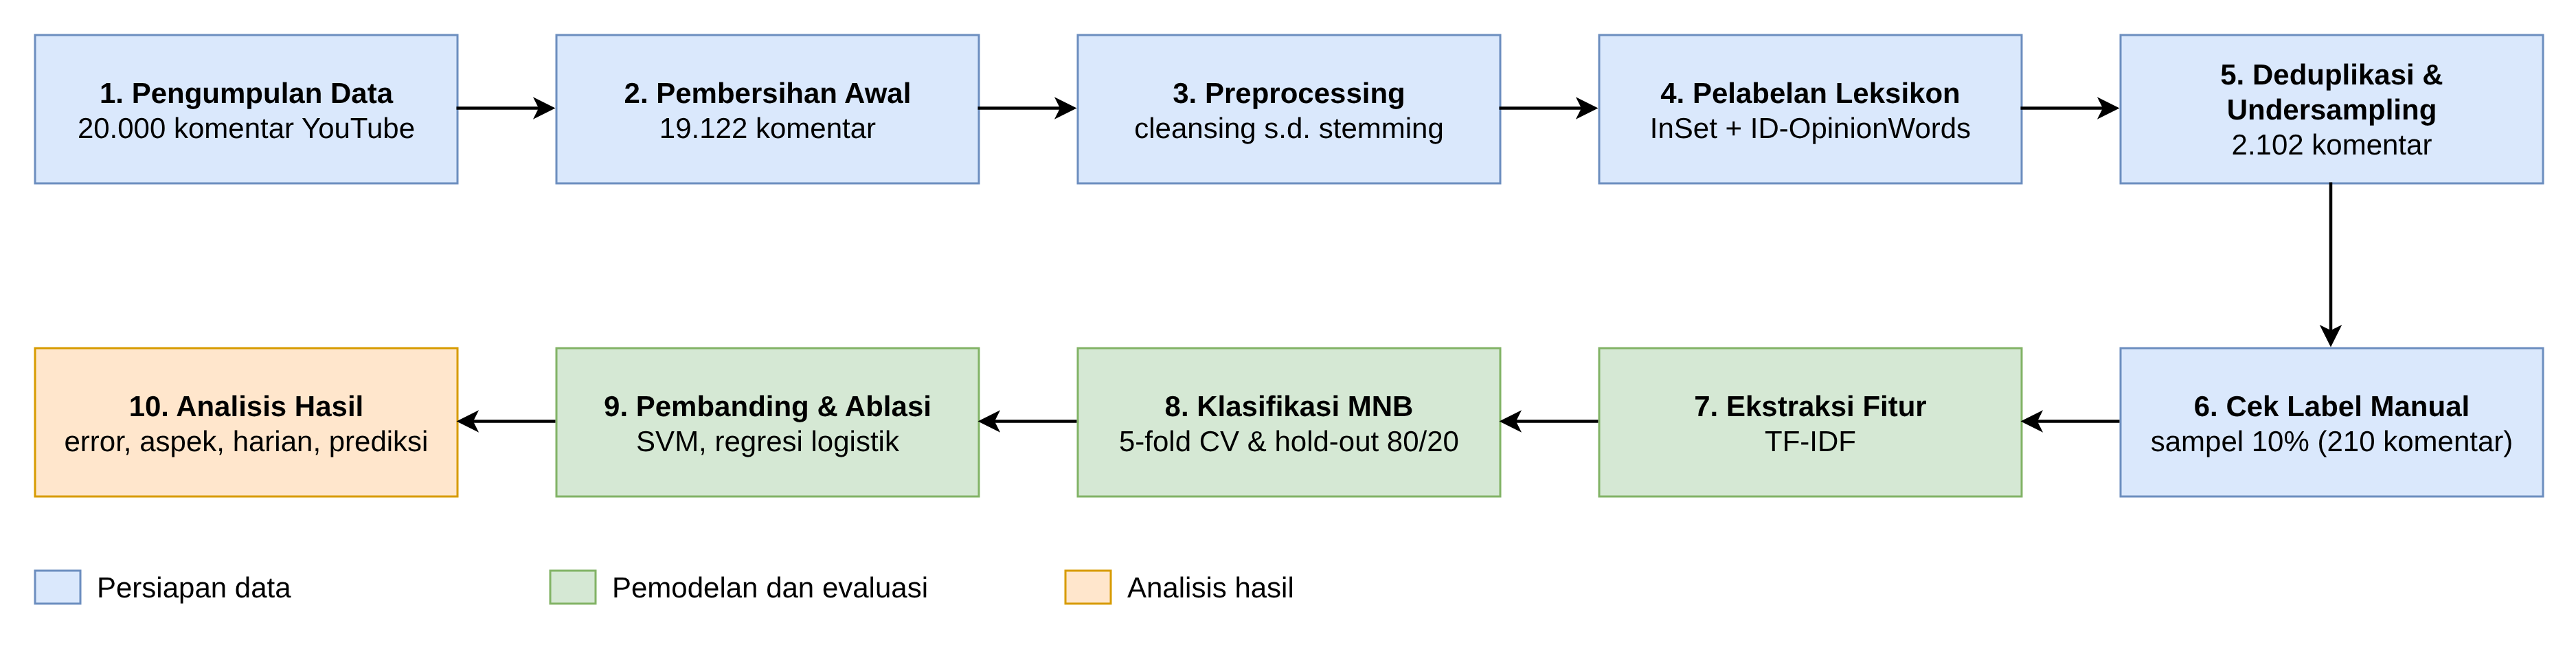

In [3]:
from IPython.display import Image
path_alur = os.path.join(BASE_DIR, "figures", "fig1_alur_penelitian.png")
if os.path.exists(path_alur):
    display(Image(filename=path_alur, width=900))
else:
    print("Gambar alur belum ada. Export dulu dari figures/drawio/fig1_alur_penelitian.drawio di draw.io")

## 2. Memuat data & memahami data

In [4]:
df_raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig", dtype=str, keep_default_na=False)
df_raw.columns = [c.strip().lstrip("﻿") for c in df_raw.columns]

def parse_like(s):
    s = str(s).strip().upper().replace(",", ".")
    if not s:
        return 0
    for k, v in {"K": 1e3, "RB": 1e3, "M": 1e6, "JT": 1e6}.items():
        if s.endswith(k):
            try: return int(round(float(s[: -len(k)]) * v))
            except ValueError: return 0
    try: return int(float(s))
    except ValueError: return 0

UNIT = {"second": "seconds", "detik": "seconds", "minute": "minutes", "menit": "minutes",
        "hour": "hours", "jam": "hours", "day": "days", "hari": "days",
        "week": "weeks", "minggu": "weeks", "month": "months", "bulan": "months",
        "year": "years", "tahun": "years"}
def parse_time(s):
    m = re.search(r"(\d+)\s*(second|detik|minute|menit|hour|jam|day|hari|week|minggu|month|bulan|year|tahun)", str(s).lower())
    if not m:
        return pd.NaT
    n, unit = int(m.group(1)), UNIT[m.group(2)]
    if unit == "months": return CRAWL_TIME - pd.Timedelta(days=30 * n)
    if unit == "years":  return CRAWL_TIME - pd.Timedelta(days=365 * n)
    return CRAWL_TIME - pd.Timedelta(**{unit: n})

df = pd.DataFrame({
    "comment_no": np.arange(len(df_raw)),
    "text_original": df_raw["text_original"].astype(str),
    "likes": df_raw["like_count"].map(parse_like),
    "edited": df_raw["time"].str.contains("edited", case=False),
    "est_time": df_raw["time"].map(parse_time),
})
df["is_reply"] = df["text_original"].str.strip().str.startswith("@")   # balasan ke komentar lain
df["est_date"] = df["est_time"].dt.date
df = df[df["text_original"].str.strip() != ""].reset_index(drop=True)   # nama akun tidak dipakai
df["n_words_raw"] = df["text_original"].str.split().str.len()

print(f"Komentar hasil crawling : {fmt_int(N_CRAWL)}")
print(f"Setelah pembersihan awal: {fmt_int(len(df))} ({fmt_int(N_CRAWL - len(df))} komentar kosong dibuang)")
print(f"Balasan (reply)         : {fmt_int(df['is_reply'].sum())} ({fmt_pct(df['is_reply'].mean() * 100)})")
print(f"Komentar diedit         : {fmt_int(df['edited'].sum())}")
print(f"Rentang tanggal (perk.) : {df['est_date'].min()} s.d. {df['est_date'].max()}")
print(f"Rata-rata kata/komentar : {fmt_dec(df['n_words_raw'].mean(), 1)}")
print(f"Median like             : {fmt_int(df['likes'].median())} (maks {fmt_int(df['likes'].max())})")
df.head()

Komentar hasil crawling : 20.000
Setelah pembersihan awal: 19.122 (878 komentar kosong dibuang)
Balasan (reply)         : 243 (1,3%)
Komentar diedit         : 254
Rentang tanggal (perk.) : 2026-10-26 s.d. 2026-11-02
Rata-rata kata/komentar : 5,1
Median like             : 0 (maks 555.000)


,comment_no,text_original,likes,edited,est_time,is_reply,est_date,n_words_raw
0,0,"Yang udah selesai nonton sampai habis, kumpul disini waakk. Aku sayang kalian semua!",555000,True,2026-10-26 14:20:00,False,2026-10-26,13
1,1,Yg nonton di hari minggu 1 november 2026 angkat tangan😭🗿☝️,37000,False,2026-11-01 14:20:00,False,2026-11-01,10
2,2,Yang nonton 2 november 2026 \nSenin siang coba cunggg☝️,1600,False,2026-11-02 12:20:00,False,2026-11-02,9
3,3,yang nonton tanggal 2 absen 🙋🏻‍♀️🙋🏻‍♀️,4400,False,2026-11-02 06:20:00,False,2026-11-02,6
4,4,absen yang baru nonton sekarang😭👇,420,False,2026-11-02 13:20:00,False,2026-11-02,5


## 3. Sumber leksikon
Kamus slang: *Colloquial Indonesian Lexicon* (Salsabila dkk., 2018). Leksikon sentimen: *InSet* (Koto & Rahmaningtyas, 2017). *ID-OpinionWords* (daftar kata opini bahasa Indonesia) dipakai untuk menyaring InSet: kata InSet hanya dipakai kalau ID-OpinionWords juga mencatatnya sebagai kata opini dengan polaritas yang sama.

In [5]:
URLS = {
    "kamus_alay.csv": "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv",
    "inset_positive.tsv": "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv",
    "inset_negative.tsv": "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv",
    "opinion_positive.txt": "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/positive.txt",
    "opinion_negative.txt": "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/negative.txt",
}
for fname, url in URLS.items():
    path = os.path.join(RES_DIR, fname)
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
print("Leksikon siap:", sorted(os.listdir(RES_DIR)))

Leksikon siap: ['inset_negative.tsv', 'inset_positive.tsv', 'kamus_alay.csv', 'opinion_negative.txt', 'opinion_positive.txt']


## 4. Preprocessing 6 tahap
Cleansing → case folding → tokenizing → normalisasi → stopword removal → stemming, sama dengan artikel Gauth.

In [6]:
# ---------- Normalisasi ----------
kamus = pd.read_csv(os.path.join(RES_DIR, "kamus_alay.csv"))
NORM = {str(s).strip().lower(): str(f).strip().lower()
        for s, f in zip(kamus["slang"], kamus["formal"]) if str(s).strip() and str(f).strip()}
# Entri khusus komentar KHW / YouTube (bisa ditambah)
CUSTOM_NORM = {
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "engga": "tidak", "tdk": "tidak", "kagak": "tidak", "g": "tidak", "gaenak": "tidak enak",
    "vidio": "video", "vidionya": "videonya", "vid": "video", "nad": "nadia", "nadd": "nadia",
    "bgt": "banget", "bngt": "banget", "bgtt": "banget", "bangett": "banget", "bet": "banget",
    "makasih": "terima kasih", "makasi": "terima kasih", "makasii": "terima kasih", "mksh": "terima kasih",
    "thanks": "terima kasih", "thank": "terima kasih", "thx": "terima kasih", "tq": "terima kasih",
    "serem": "seram", "nangis": "menangis", "sampe": "sampai", "ampe": "sampai", "blm": "belum",
    "udh": "sudah", "udah": "sudah", "dah": "sudah", "pls": "tolong", "gess": "guys", "gaes": "guys",
    "cungg": "cung", "eps": "episode", "ep": "episode", "epsd": "episode",
    "goks": "keren", "gokil": "keren", "kece": "keren", "best": "terbaik", "the": "", "love": "suka",
    "lope": "suka", "seruu": "seru", "sukaa": "suka", "bagusss": "bagus", "mantul": "mantap",
}
NORM.update(CUSTOM_NORM)

# ---------- Stopword ----------
KEEP_WORDS = {"tidak", "belum", "nggak", "tanpa", "bisa", "guna", "bukan", "kurang"}  # negasi & kemampuan
SASTRAWI_SW = set(StopWordRemoverFactory().get_stop_words())
EXTRA_SW = {"sih", "deh", "nya", "dong", "kok", "nih", "yah", "ya", "yaa", "kan", "lho", "loh", "tuh", "mah",
            "kah", "pun", "yuk", "ayo", "hehe", "wkwk", "haha", "hihi", "ah", "eh", "oh", "aduh", "wah",
            "aku", "saya", "kamu", "kalian", "gue", "lu", "lo", "kita", "kami", "dia", "mereka", "ku", "mu",
            "kak", "ka", "kakak", "wak", "wawak", "guys", "min", "bang", "mbak", "mas", "teh",
            "khw", "nadia", "omara", "the", "and", "you", "of", "aja", "saja", "juga", "lagi", "sama",
            "udah", "sudah", "banget", "gitu", "begitu", "gini", "begini", "kayak", "seperti", "cuma",
            "allah", "part", "pokok", "pokoknya", "hari", "kali", "wkwkwk", "dari"}
STOPWORDS = (SASTRAWI_SW | EXTRA_SW) - KEEP_WORDS
STOPWORDS_NONEG = SASTRAWI_SW | EXTRA_SW            # ablasi: kata negasi ikut dibuang

# ---------- Stemming ----------
_stemmer = StemmerFactory().create_stemmer()
STEM_OVERRIDE = {"perbaiki": "perbaik", "menangis": "tangis", "nangis": "tangis", "penyampaian": "sampai",
                 "merinding": "merinding", "pasangan": "pasangan", "menonton": "tonton", "nonton": "tonton",
                 "ditonton": "tonton", "tontonan": "tonton", "terharu": "haru", "keren": "keren"}
_stem_cache = {}
def stem_word(w):
    if w in STEM_OVERRIDE: return STEM_OVERRIDE[w]
    if w not in _stem_cache: _stem_cache[w] = _stemmer.stem(w)
    return _stem_cache[w]

# ---------- 6 tahap ----------
def cleansing(text):
    t = unicodedata.normalize("NFKC", str(text))           # huruf bergaya -> huruf biasa
    t = emoji.replace_emoji(t, replace=" ")
    t = re.sub(r"http\S+|www\.\S+", " ", t)                  # URL
    t = re.sub(r"@[\w\.\-]+", " ", t)                        # mention / reply
    t = re.sub(r"[^A-Za-z\s]", " ", t)                       # angka, tanda baca, simbol
    t = re.sub(r"([A-Za-z])\1{2,}", r"\1", t)                # iniiiii -> ini
    return re.sub(r"\s+", " ", t).strip()

def case_folding(t):  return t.lower()
def tokenizing(t):    return t.split()
def normalization(tokens):
    out = []
    for w in tokens:
        out.extend(NORM.get(w, w).split())
    return out
def stopword_removal(tokens, sw=None):
    sw = STOPWORDS if sw is None else sw
    return [w for w in tokens if w not in sw and len(w) > 1]
def stemming(tokens): return [stem_word(w) for w in tokens]

def preprocess(text, steps=False, normalize=True, sw=None):
    s1 = cleansing(text); s2 = case_folding(s1); s3 = tokenizing(s2)
    s4 = normalization(s3) if normalize else s3
    s5 = stopword_removal(s4, sw); s6 = stemming(s5)
    if steps:
        return {"Teks asli": text, "Cleansing": s1, "Case folding": s2, "Tokenizing": s3,
                "Normalisasi": s4, "Stopword removal": s5, "Stemming": s6}
    return s4, s6

print("Jumlah stopword:", len(STOPWORDS))

Jumlah stopword: 182


In [7]:
print("Memproses teks... (Sastrawi + cache, biasanya 1-3 menit untuk 20 ribu komentar)")
res = df["text_original"].map(preprocess)
df["tokens_norm"] = res.str[0]
df["text_norm"] = df["tokens_norm"].str.join(" ")
df["text_final"] = res.str[1].str.join(" ")
# Varian untuk ablasi
df["text_noneg"] = df["text_original"].map(lambda t: " ".join(preprocess(t, sw=STOPWORDS_NONEG)[1]))
df["text_nonorm"] = df["text_original"].map(lambda t: " ".join(preprocess(t, normalize=False)[1]))
print("Selesai.")

# Tabel 2: contoh satu komentar melewati 6 tahap
EXAMPLE_PREPROCESS = None    # isi teks sendiri jika ingin contoh tertentu
if EXAMPLE_PREPROCESS is None:
    cand = df[df["text_original"].str.contains(r"[^\x00-\x7F]") &
              df["text_original"].str.contains(r"\b(?:bgt|gak|ga|yg|makasih|nangis)\b", case=False) &
              df["text_original"].map(lambda t: bool(re.search(r"([A-Za-z])\1{2,}", t))) &
              df["n_words_raw"].between(8, 20) & ~df["is_reply"]]
    EXAMPLE_PREPROCESS = (cand if len(cand) else df).iloc[0]["text_original"]
tab2 = pd.DataFrame([(k, v if isinstance(v, str) else "[" + ", ".join(v) + "]")
                     for k, v in preprocess(EXAMPLE_PREPROCESS, steps=True).items()], columns=["Tahap", "Hasil"])
save_table(tab2, "tabel2_contoh_preprocessing.csv")
tab2

Memproses teks... (Sastrawi + cache, biasanya 1-3 menit untuk 20 ribu komentar)


Selesai.


,Tahap,Hasil
0,Teks asli,"makasih ya kak nad, sukses sllu, sehat sellu panjang usia utk kak nad dan semua tim \nlup yuuu 🤗🤗🤗"
1,Cleansing,makasih ya kak nad sukses sllu sehat sellu panjang usia utk kak nad dan semua tim lup yu
2,Case folding,makasih ya kak nad sukses sllu sehat sellu panjang usia utk kak nad dan semua tim lup yu
3,Tokenizing,"[makasih, ya, kak, nad, sukses, sllu, sehat, sellu, panjang, usia, utk, kak, nad, dan, semua, tim, lup, yu]"
4,Normalisasi,"[terima, kasih, ya, kak, nadia, sukses, selalu, sehat, sellu, panjang, usia, untuk, kak, nadia, dan, semua, tim, lup..."
5,Stopword removal,"[terima, kasih, sukses, selalu, sehat, sellu, panjang, usia, semua, tim, lup]"
6,Stemming,"[terima, kasih, sukses, selalu, sehat, sellu, panjang, usia, semua, tim, lup]"


## 5. Pelabelan leksikon (InSet + ID-OpinionWords) dan negasi
Skor = jumlah bobot kata/frasa yang cocok (frasa hingga 3 kata, cocok terpanjang dahulu). Kata negasi (*tidak, bukan, belum, kurang, jangan, tanpa*) membalik bobot kata sentimen pertama dalam jarak dua token sesudahnya. Skor > 0 → positif, < 0 → negatif, 0 → netral (dikeluarkan). 

Leksikon dibangun dalam tiga langkah:
1. **Konsensus dua leksikon.** Kata InSet dipakai hanya kalau ID-OpinionWords juga mencatatnya dengan polaritas yang sama; kata ID-OpinionWords yang tidak ada di InSet diberi bobot ±3. Langkah ini membuang bobot InSet yang tidak bermakna sentimen di komentar ini, seperti *mau* (+4), *apa* (−3), dan *tata* (+1, nama tokoh di cerita).
2. **Kata netral konteks.** Kata fungsi dan kata yang netral di komentar video (*menonton*, *durasi*, *panjang*, *gua*, *jujur*) dikeluarkan.
3. **Penyesuaian domain.** Beberapa kata YouTube ditambahkan atau diberi bobot ulang (*gong*, *seru*, *mantap*, *bosan*, *jelek*).

Label yang dihasilkan adalah **polaritas teks**: rasa takut, sedih, dan merinding dihitung negatif. Set `NEUTRALIZE_STORY_EMOTION = True` untuk menolkan kata emosi tersebut.

In [8]:
def read_lex(path):
    t = pd.read_csv(path, sep="\t")
    return {str(w).strip().lower(): int(v) for w, v in zip(t["word"], t["weight"])}
ins_pos = read_lex(os.path.join(RES_DIR, "inset_positive.tsv"))
ins_neg = read_lex(os.path.join(RES_DIR, "inset_negative.tsv"))
def read_list(path):
    with open(path, encoding="utf-8", errors="ignore") as f:
        return {l.strip().lower() for l in f if l.strip() and not l.startswith(";")}
op_pos = read_list(os.path.join(RES_DIR, "opinion_positive.txt"))
op_neg = read_list(os.path.join(RES_DIR, "opinion_negative.txt"))

# Langkah 1: konsensus InSet dan ID-OpinionWords
LEX, n_conflict, n_inset = {}, 0, 0
for w in set(ins_pos) | set(ins_neg):
    p, n = ins_pos.get(w, 0), ins_neg.get(w, 0)
    if p and n:
        n_conflict += 1
        v = p if (w in op_pos and w not in op_neg) else n if (w in op_neg and w not in op_pos) else p + n
    else:
        v = p + n
    if (v > 0 and w in op_pos and w not in op_neg) or (v < 0 and w in op_neg and w not in op_pos):
        LEX[w] = v; n_inset += 1
for w in op_pos - op_neg: LEX.setdefault(w, 3)
for w in op_neg - op_pos: LEX.setdefault(w, -3)

# Penyesuaian domain komentar YouTube hiburan (dicatat di bagian metode)
DOMAIN_LEX = {"seru": 4, "keren": 4, "mantap": 4, "gong": 3, "suka": 3, "bagus": 3, "terbaik": 4,
              "terima kasih": 4, "salut": 4, "juara": 3, "semangat": 3, "sukses": 3, "sayang": 3,
              "rekomendasi": 3, "candu": 3, "puas": 4, "jelas": 2, "lucu": 3, "sehat": 3,
              "bosan": -4, "membosankan": -4, "jelek": -4, "kecewa": -4, "garing": -3,
              "lebay": -3, "iklan": -2, "clickbait": -4}
STORY_EMOTION = {"sedih", "seram", "merinding", "takut", "ngeri", "menangis", "tangis", "haru", "terharu",
                 "kasihan", "mati", "meninggal", "sakit", "kesal", "greget", "geram", "marah", "emosi",
                 "nyesek", "sesak", "kaget", "horor", "mistis", "tragis", "pilu", "air mata",
                 "menguras", "pecah", "duka", "berduka", "innalillahi"}
NEGATORS = {"tidak", "bukan", "belum", "kurang", "jangan", "tanpa"}
# InSet memberi bobot pada kata fungsi ("yang" -5, "ya" +4) dan kata yang netral di
# konteks ini ("menonton" -4, "allah" +5). Kata-kata ini dikeluarkan dari leksikon.
NEUTRAL_DOMAIN = {"menonton", "nonton", "tonton", "ditonton", "video", "videonya", "durasi", "episode",
                  "part", "jam", "menit", "hari", "selesai", "sampai", "semua", "cerita", "ceritanya",
                  "kisah", "allah", "tuhan", "team", "tim", "air", "mata", "sering", "memang", "pokoknya",
                  "pokok", "sangat", "sekali", "baru", "lama", "habis", "kumpul", "angkat", "tangan",
                  "absen", "hadir", "tanggal", "minggu", "senin", "selasa", "rabu", "kamis", "jumat",
                  "sabtu", "pagi", "siang", "sore", "malam", "november", "oktober", "opening", "narasumber",
                  "korban", "buat", "sebuah", "sungguh", "mulai", "lanjut", "sengaja", "tidur", "makan",
                  "badan", "sebadan", "biasa", "biasanya", "kali", "banyak", "amin", "aamiin",
                  "benar", "benaran", "gua", "hampir", "sendirian", "ih", "siap", "panjang", "panjangnya",
                  "sepanjang", "asli", "makin", "tetap", "ulang", "mungkin", "sebenarnya", "lupa", "jauh",
                  "berarti", "fajar", "secara", "terlalu", "keluar", "sedikit", "serius", "besar", "semuanya",
                  "kecil", "berat", "cepat", "terima", "energi", "kaya", "goreng", "menahan", "menetes", "jatuh",
                  "hati", "gila", "sok", "ketinggalan", "jujur", "kepanjangan", "tata"}
FUNCTION_WORDS = (SASTRAWI_SW | EXTRA_SW | NEGATORS | NEUTRAL_DOMAIN) - set(DOMAIN_LEX)
LEX = {w: v for w, v in LEX.items() if not all(t in FUNCTION_WORDS for t in w.split())}
LEX.update(DOMAIN_LEX)
if NEUTRALIZE_STORY_EMOTION:
    for w in STORY_EMOTION: LEX[w] = 0
LEX = {w: v for w, v in LEX.items() if v != 0 or w in STORY_EMOTION}
MAX_N = 3
print(f"Leksikon akhir: {fmt_int(len(LEX))} entri ({fmt_int(n_inset)} dari InSet yang dikonfirmasi ID-OpinionWords)")

def lexicon_score(tokens):
    score, hits, i, last_neg = 0, [], 0, -99
    while i < len(tokens):
        if tokens[i] in NEGATORS:
            last_neg = i; i += 1; continue
        matched = False
        for n in range(MAX_N, 0, -1):
            if i + n > len(tokens): continue
            phrase = " ".join(tokens[i:i + n])
            w = LEX.get(phrase)
            if w is None and n == 1:
                w = LEX.get(stem_word(phrase))            # coba bentuk dasar
            if w is not None:
                if w != 0 and i - last_neg <= 2:          # negasi membalik kata sentimen pertama sesudahnya
                    w = -w; last_neg = -99
                score += w; hits.append(f"{phrase}({w:+d})")
                i += n; matched = True; break
        if not matched: i += 1
    return score, hits

sc = df["tokens_norm"].map(lexicon_score)
df["lex_score"] = sc.str[0]; df["lex_hits"] = sc.str[1].str.join(" ")
df["label"] = np.select([df["lex_score"] > 0, df["lex_score"] < 0], ["positive", "negative"], "neutral")

# Tabel 1: distribusi label hasil leksikon
order = ["positive", "negative", "neutral"]
tab1 = pd.DataFrame({
    "Label": [NAMA[k] for k in order],
    "Komentar": [int((df.label == k).sum()) for k in order],
    "Persen (%)": [round((df.label == k).mean() * 100, 1) for k in order],
    "Rata-rata kata": [round(df.loc[df.label == k, "n_words_raw"].mean(), 1) for k in order],
    "Median like": [df.loc[df.label == k, "likes"].median() for k in order],
    "Keterangan": ["Dipakai", "Dipakai", "Dikeluarkan"],
})
tab1.loc[len(tab1)] = ["Total", len(df), 100.0, round(df["n_words_raw"].mean(), 1), df["likes"].median(), ""]
save_table(tab1, "tabel1_distribusi_label.csv"); display(tab1)
# Semua komentar beserta skor dan label leksikon
save_table(df[["comment_no", "text_original", "likes", "est_date", "is_reply", "lex_score", "lex_hits", "label",
               "text_norm", "text_final"]], "khw400_semua_komentar_berlabel.csv")

# Kata leksikon yang paling sering menentukan skor (untuk memeriksa leksikon)
hit_words = Counter(h.rsplit("(", 1)[0] for hs in sc.str[1] for h in hs if not h.endswith("(+0)"))
top_hits = pd.DataFrame([(w, n, LEX.get(w, LEX.get(stem_word(w)))) for w, n in hit_words.most_common(30)],
                        columns=["kata/frasa", "frekuensi", "bobot"])
save_table(top_hits, "kata_leksikon_tersering.csv")
for lab in order:
    print(f"\nContoh {NAMA[lab].lower()}:")
    display(df[df.label == lab].sample(min(5, (df.label == lab).sum()), random_state=SEED)[["text_original", "lex_score", "lex_hits"]])

Leksikon akhir: 3.262 entri (969 dari InSet yang dikonfirmasi ID-OpinionWords)


,Label,Komentar,Persen (%),Rata-rata kata,Median like,Keterangan
0,Positif,1169,6.1,13.4,0.0,Dipakai
1,Negatif,1482,7.8,12.3,0.0,Dipakai
2,Netral,16471,86.1,3.8,0.0,Dikeluarkan
3,Total,19122,100.0,5.1,0.0,



Contoh positif:


,text_original,lex_score,lex_hits
7347,thanks or thank you,8,terima kasih(+4) terima kasih(+4)
17173,Andai ini dibuat film bioskop seru kali,4,seru(+4)
197,Puas untuk malam ini dengan kisah yg sedih dan pelajaran yg sangat berharga atas semua hal yg sangat berarti makasih...,6,puas(+4) sedih(-5) sangat berharga(+3) terima kasih(+4)
235,"KERENN BANGETTT KAA NADD, HUHUU LOVEE UU SOO MUCHHH🥹💗",4,keren(+4)
13336,Alhamdulillah baru aja kelarrr wak 😂,5,alhamdulillah(+5)



Contoh negatif:


,text_original,lex_score,lex_hits
848,"wakk sedih, seram jdi satu huhu",-9,sedih(-5) seram(-4)
5406,Baruu mau mulai gk ada tmn merinding seluruh tubuh😢😅,-3,merinding(-3)
12703,Sedih pool😢😢,-5,sedih(-5)
6961,Sedih ya mana nama samarannya Santi itu namaku 😂,-10,sedih(-5) samarannya(-5)
18070,"engga kak wkwkwk😭 aku nemplok ke mama, terus ganti lagi ke ayah. merinding banget soalnyaaa",-3,merinding(-3)



Contoh netral:


,text_original,lex_score,lex_hits
7485,Cerita itu sudah belasan tahun. Berarti sekarang Tata sudah remaja 😭😭,0,
10886,Aku dari pagi trus aku jeda lanjut jam 16:32,0,
15898,"aku lg nnton jm 10.30 , barengn yuuu",0,
16913,haikak ini baru seleesai nonton sambil makan,0,
10305,sama wak saking gada tontona baru,0,


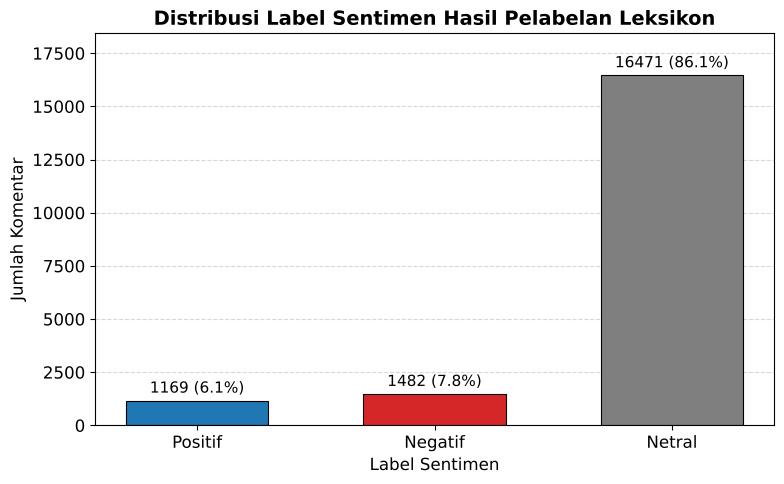

In [9]:
# Gambar 2: distribusi label
jumlah = [int((df.label == k).sum()) for k in order]
plt.figure(figsize=(8, 5))
bars = plt.bar([NAMA[k] for k in order], jumlah, color=[WARNA[k] for k in order],
               edgecolor="black", linewidth=0.8, width=0.6)
for bar, n in zip(bars, jumlah):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
             f"{n} ({n / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=11)
plt.title("Distribusi Label Sentimen Hasil Pelabelan Leksikon", fontsize=14, fontweight="bold")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Komentar")
plt.ylim(0, max(jumlah) * 1.12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.tight_layout()
save("fig2_distribusi_label.png")

## 6. Deduplikasi & undersampling
Teks yang identik setelah preprocessing digabung dengan label mayoritas; teks berlabel seri dibuang. Kelas mayoritas lalu diambil acak sebanyak kelas minoritas.

In [10]:
lab = df[(df["label"] != "neutral") & (df["text_final"].str.strip() != "")].copy()
n_labelled = int((df["label"] != "neutral").sum())
n_empty = n_labelled - len(lab)

def majority(s):
    c = s.value_counts()
    return None if len(c) > 1 and c.iloc[0] == c.iloc[1] else c.index[0]
maj = lab.groupby("text_final")["label"].agg(majority)
n_tie = int(maj.isna().sum())
dedup = (lab.drop_duplicates("text_final").set_index("text_final")
            .assign(label=maj).dropna(subset=["label"]).reset_index())
counts = dedup["label"].value_counts()
n_min = int(counts.min())
data = (pd.concat([g.sample(n=n_min, random_state=SEED) for _, g in dedup.groupby("label")])
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
n_merged = len(lab) - len(dedup) - n_tie

print(f"Komentar berlabel (non-netral)      : {fmt_int(n_labelled)}")
print(f"Teks kosong setelah preprocessing   : {fmt_int(n_empty)}")
print(f"Setelah deduplikasi                 : {fmt_int(len(dedup))}  ({fmt_int(n_merged)} duplikat digabung, {n_tie} seri dibuang)")
print(f"  negatif {fmt_int(counts.get('negative', 0))} | positif {fmt_int(counts.get('positive', 0))}")
print(f"Dataset seimbang akhir              : {fmt_int(len(data))} ({fmt_int(n_min)} per kelas)")
save_table(data[["comment_no", "text_original", "likes", "est_date", "lex_score", "label", "text_norm", "text_final"]],
           "khw400_dataset_final.csv")

Komentar berlabel (non-netral)      : 2.651
Teks kosong setelah preprocessing   : 0
Setelah deduplikasi                 : 2.398  (253 duplikat digabung, 0 seri dibuang)
  negatif 1.347 | positif 1.051
Dataset seimbang akhir              : 2.102 (1.051 per kelas)


,comment_no,text_original,likes,est_date,lex_score,label,text_norm,text_final
0,4830,stock temen setrika dan makan aman❤❤❤,0,2026-10-26,3,positive,stock teman setrika dan makan aman,stock teman setrika makan aman
1,7470,"tata🥺🥺 semangat ya sayang , jangan nyerah yaa",2,2026-10-29,6,positive,tata semangat ya sayang jangan nyerah ya,tata semangat sayang jangan nyerah
2,709,Baru selesai wak ikut emosi ikut sedih campur aduk 🥹,0,2026-10-26,-5,negative,baru selesai wak ikut emosi ikut sedih campur aduk,baru selesai ikut emosi ikut sedih campur aduk
3,17335,"first time nonton nadia omara akuu, plis takut seremm bgttt ga guys",0,2026-10-27,-4,negative,first time menonton nadia omara aku plis takut seremm banget tidak guys,first time tonton plis takut seremm tidak
4,2955,Seru banget vidio nya,0,2026-11-01,4,positive,seru banget video nya,seru video
...,...,...,...,...,...,...,...,...
2097,6113,Kasih syg Allah emg sebesar itu sama hamba nya bahkan melebihi kasih syg seorang ibu ke anak nya…,3,2026-10-30,13,positive,kasih sayang allah memang sebesar itu sama hamba nya bahkan melebihi kasih sayang seorang ibu ke anak nya,kasih sayang memang besar hamba bahkan lebih kasih sayang orang ibu anak
2098,279,PUAS KALII BAHH DURASINYAA,0,2026-10-26,4,positive,puas kali bahh durasinyaa,puas bahh durasinyaa
2099,4872,Ngakak bgt durasi jumbo😭🤣🤣 tp emang puasss bgt ya wakkk🤣🫶🏻,0,2026-10-26,4,positive,mengakak banget durasi jumbo tapi memang puas banget ya wak,akak durasi jumbo memang puas
2100,3805,Gong banget inii\nThank you wak nad🥺❤❤,0,2026-10-26,7,positive,gong banget ini terima kasih you wak nadia,gong terima kasih


## 7. Cek label manual (10% sampel berstrata)
File `hasil/cek_label_sampel.csv` diekspor. Buka di Google Sheets/Excel, isi kolom `cek_manual` dengan **sesuai**, **bertentangan**, atau **tidak jelas**, simpan dengan nama yang sama, lalu jalankan sel berikutnya. Kolom `pemeriksa` mencatat siapa yang mengisi.

In [11]:
CHECK_PATH = os.path.join(OUT_DIR, "cek_label_sampel.csv")
n_check = int(round(0.10 * len(data))) // 2 * 2
if not os.path.exists(CHECK_PATH):           # jangan menimpa hasil isian manual
    sample = data.groupby("label").sample(n=min(n_min, n_check // 2), random_state=SEED)
    sample = sample[["comment_no", "text_original", "label", "lex_score", "lex_hits"]].assign(cek_manual="", catatan="")
    sample.to_csv(CHECK_PATH, index=False)
    print(f"Sampel {len(sample)} komentar diekspor ke {rel(CHECK_PATH)}")
    if IN_COLAB:
        from google.colab import files; files.download(CHECK_PATH)
else:
    print("File cek label sudah ada, tidak ditimpa:", rel(CHECK_PATH))

File cek label sudah ada, tidak ditimpa: hasil/cek_label_sampel.csv


In [12]:
chk = pd.read_csv(CHECK_PATH, keep_default_na=False)
filled = chk[chk["cek_manual"].str.strip() != ""]
if len(filled) == 0:
    print("Kolom cek_manual belum diisi. Isi dulu, lalu jalankan ulang sel ini.")
else:
    v = filled["cek_manual"].str.strip().str.lower()
    cek = v.value_counts().rename_axis("Hasil").to_frame("Jumlah")
    cek["Persen (%)"] = (cek["Jumlah"] / len(filled) * 100).round(1)
    print(f"Label leksikon sesuai dengan teks: {fmt_pct((v == 'sesuai').mean() * 100)} dari {len(filled)} komentar")
    display(cek)
    ct = pd.crosstab(filled["label"].map(NAMA), v)
    save_table(ct, "rekap_cek_label.csv", index=True); display(ct)

Label leksikon sesuai dengan teks: 72,4% dari 210 komentar


,Jumlah,Persen (%)
Hasil,,
sesuai,152,72.4
tidak jelas,43,20.5
bertentangan,15,7.1


cek_manual,bertentangan,sesuai,tidak jelas
label,,,
Negatif,6,76,23
Positif,9,76,20


## 8. Statistik token, word cloud (Gambar 3) & kata teratas (Gambar 4)

Total token: 17.804 | kata unik: 2.813
  Negatif: 8.628 token (48%)
  Positif: 9.176 token (52%)


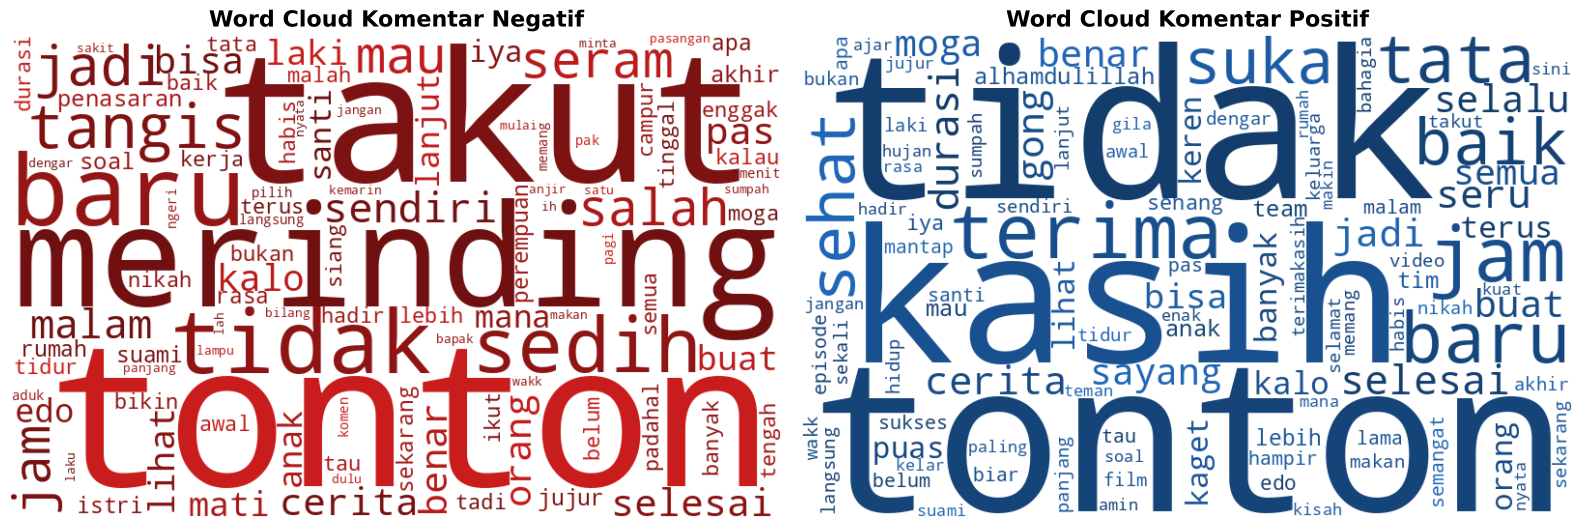

,Negatif,Positif
0,tonton (344),tonton (220)
1,takut (274),tidak (210)
2,merinding (178),kasih (168)
3,baru (169),terima (150)
4,tidak (161),jam (150)
5,sedih (140),baru (128)
6,tangis (124),tata (115)
7,jadi (102),sehat (105)
8,seram (87),baik (104)
9,jam (85),suka (101)


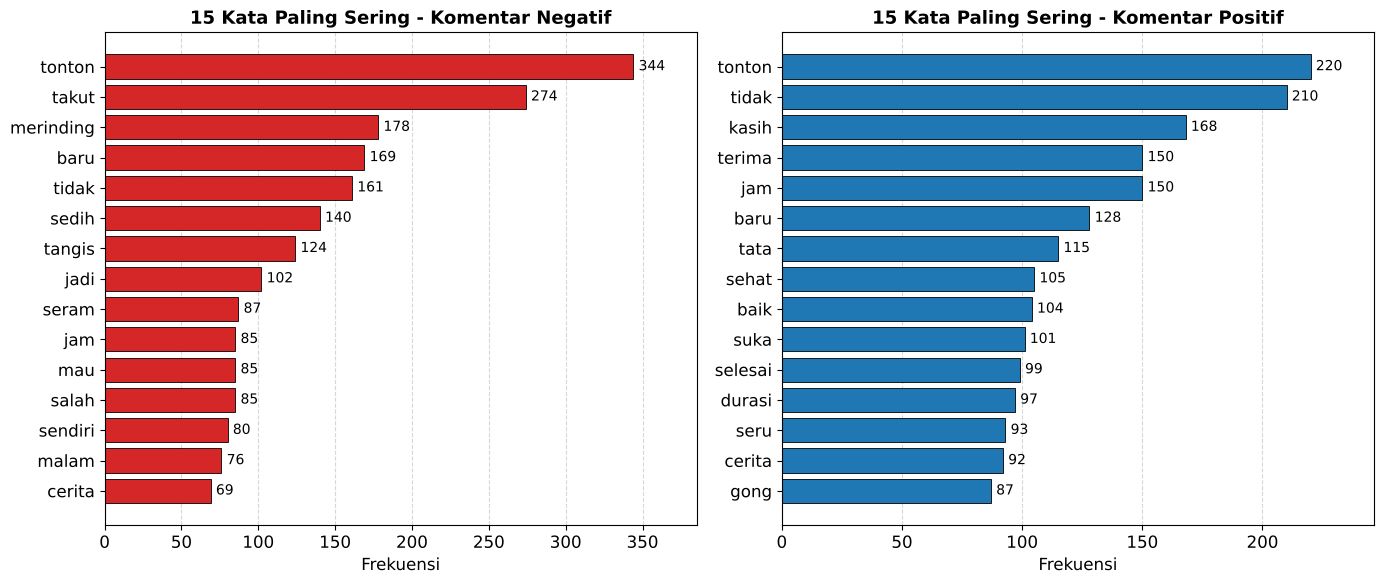

In [13]:
tok = {c: Counter(" ".join(data.loc[data.label == c, "text_final"]).split()) for c in LABELS}
all_tok = tok["negative"] + tok["positive"]
n_tok = {c: sum(tok[c].values()) for c in LABELS}
print(f"Total token: {fmt_int(sum(all_tok.values()))} | kata unik: {fmt_int(len(all_tok))}")
for c in LABELS:
    print(f"  {NAMA[c]}: {fmt_int(n_tok[c])} token ({fmt_pct(n_tok[c] / sum(all_tok.values()) * 100, 0)})")

def warna_merah(word, font_size, position, orientation, random_state=None, **kwargs):
    return "hsl(0, 75%%, %d%%)" % random_state.randint(25, 45)

def warna_biru(word, font_size, position, orientation, random_state=None, **kwargs):
    return "hsl(212, 70%%, %d%%)" % random_state.randint(25, 42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, c, fungsi_warna in zip(axes, LABELS, [warna_merah, warna_biru]):
    wc = WordCloud(width=800, height=500, background_color="white", max_words=100,
                   random_state=SEED).generate_from_frequencies(tok[c])
    ax.imshow(wc.recolor(color_func=fungsi_warna, random_state=SEED), interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"Word Cloud Komentar {NAMA[c]}", fontsize=16, fontweight="bold")
plt.tight_layout()
save("fig3_wordcloud.png")

top = pd.DataFrame({
    "Negatif": [f"{w} ({n})" for w, n in tok["negative"].most_common(15)],
    "Positif": [f"{w} ({n})" for w, n in tok["positive"].most_common(15)]})
save_table(top, "top15_kata_per_kelas.csv"); display(top)

# Gambar 4: 15 kata teratas per kelas
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, c in zip(axes, LABELS):
    kata, frek = zip(*tok[c].most_common(15))
    ax.barh(kata[::-1], frek[::-1], color=WARNA[c], edgecolor="black", linewidth=0.6)
    for i, n in enumerate(frek[::-1]):
        ax.text(n + max(frek) * 0.01, i, str(n), va="center", fontsize=10)
    ax.set_title(f"15 Kata Paling Sering - Komentar {NAMA[c]}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Frekuensi")
    ax.set_xlim(0, max(frek) * 1.12)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
plt.tight_layout()
save("fig4_kata_teratas.png")

## 9. Perhitungan manual Multinomial Naïve Bayes (Tabel 3)
Likelihood memakai hitungan kata dengan Laplace smoothing (α = 1), sesuai Persamaan 3–4 di artikel Gauth.

In [14]:
cv_all = CountVectorizer()
X_cnt = cv_all.fit_transform(data["text_final"])
mnb_cnt = MultinomialNB(alpha=1.0).fit(X_cnt, data["label"])
vocab = cv_all.vocabulary_
cls = list(mnb_cnt.classes_)
iN, iP = cls.index("negative"), cls.index("positive")
loglik, prior = mnb_cnt.feature_log_prob_, mnb_cnt.class_log_prior_
print(f"Prior: P(neg) = {np.exp(prior[iN]):.4f}, P(pos) = {np.exp(prior[iP]):.4f}; |V| = {fmt_int(len(vocab))}")

cnt = mnb_cnt.feature_count_
ratio = loglik[iN] - loglik[iP]
inv = {i: w for w, i in vocab.items()}
EXAMPLE_WORD = None          # isi kata sendiri jika ingin contoh tertentu
if EXAMPLE_WORD is None:     # kata negatif paling khas yang muncul >= 20 kali
    idx_sorted = [i for i in np.argsort(-ratio) if cnt[iN, i] >= 20] or [int(np.argmax(ratio))]
    EXAMPLE_WORD = inv[idx_sorted[0]]
j = vocab[EXAMPLE_WORD]
pn, pp = np.exp(loglik[iN, j]), np.exp(loglik[iP, j])
ev = 0.5 * pn + 0.5 * pp
word_calc = {"kata": EXAMPLE_WORD, "n_neg": int(cnt[iN, j]), "n_pos": int(cnt[iP, j]),
             "p_w_neg": pn, "p_w_pos": pp, "p_d": ev, "post_neg": 0.5 * pn / ev, "post_pos": 0.5 * pp / ev}
print(f"Contoh kata '{EXAMPLE_WORD}': muncul {word_calc['n_neg']}x di negatif, {word_calc['n_pos']}x di positif")
print(f"  P(w|neg) = {pn:.6f}, P(w|pos) = {pp:.6f}, P(D) = {ev:.5f}")
print(f"  Posterior: negatif {word_calc['post_neg']:.4f} | positif {word_calc['post_pos']:.4f}")

# Komentar contoh: komentar campuran (punya kata positif & negatif kuat), 4-8 token
EXAMPLE_COMMENT = None    # isi teks sendiri jika ingin contoh tertentu
def mixed(t):
    r = [ratio[vocab[w]] for w in t.split() if w in vocab]
    return bool(r) and max(r) > 1 and min(r) < -1
if EXAMPLE_COMMENT is None:
    pool = data[data["text_final"].str.split().str.len().between(4, 8) & data["text_final"].map(mixed)
                & (data["label"] == "negative")]
    row = (pool if len(pool) else data).iloc[0]
    EXAMPLE_COMMENT, ex_final, ex_label = row["text_original"], row["text_final"], row["label"]
else:
    ex_final, ex_label = " ".join(preprocess(EXAMPLE_COMMENT)[1]), "-"
rows = [("Prior", prior[iP], prior[iN])]
rows += [(w, loglik[iP, vocab[w]], loglik[iN, vocab[w]]) for w in ex_final.split() if w in vocab]
tab3 = pd.DataFrame(rows, columns=["Term", "ln P(t|Positif)", "ln P(t|Negatif)"])
tab3.loc[len(tab3)] = ["Skor (jumlah)", tab3["ln P(t|Positif)"].sum(), tab3["ln P(t|Negatif)"].sum()]
tab3[["ln P(t|Positif)", "ln P(t|Negatif)"]] = tab3[["ln P(t|Positif)", "ln P(t|Negatif)"]].round(4)
map_pred = "positive" if tab3.iloc[-1, 1] > tab3.iloc[-1, 2] else "negative"
print("\nKomentar contoh:", EXAMPLE_COMMENT, "\n→ token:", ex_final, "| label leksikon:", ex_label)
print("Kelas MAP:", map_pred)
save_table(tab3, "tabel3_perhitungan_map.csv"); tab3

Prior: P(neg) = 0.5000, P(pos) = 0.5000; |V| = 2.812
Contoh kata 'ngeri': muncul 22x di negatif, 0x di positif
  P(w|neg) = 0.002010, P(w|pos) = 0.000083, P(D) = 0.00105
  Posterior: negatif 0.9602 | positif 0.0398

Komentar contoh: Sakit banget jadi tata, aku sampai nangis sesegukan 😭 
→ token: sakit jadi tata tangis sesegukan | label leksikon: negative
Kelas MAP: negative


,Term,ln P(t|Positif),ln P(t|Negatif)
0,Prior,-0.6931,-0.6931
1,sakit,-7.7822,-6.4546
2,jadi,-4.9258,-4.7102
3,tata,-4.6381,-6.1669
4,tangis,-6.9938,-4.5166
5,sesegukan,-9.3917,-8.2463
6,Skor (jumlah),-34.4246,-30.7879


## 10. Evaluasi 5-fold cross-validation (Tabel 4)
Vocabulary TF-IDF dibangun hanya dari fold latih (pipeline).

In [15]:
X_all, y_all = data["text_final"].values, data["label"].values
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X_all, y_all))

def make_model(name):
    if name == "MNB, TF-IDF":   return Pipeline([("vec", TfidfVectorizer()), ("clf", MultinomialNB(alpha=1.0))])
    if name == "MNB, raw counts": return Pipeline([("vec", CountVectorizer()), ("clf", MultinomialNB(alpha=1.0))])
    if name == "Linear SVM, TF-IDF": return Pipeline([("vec", TfidfVectorizer()), ("clf", LinearSVC(C=1.0, random_state=SEED))])
    if name == "Logistic regression, TF-IDF":
        return Pipeline([("vec", TfidfVectorizer()), ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=SEED))])
    raise ValueError(name)

def run_cv(name, X=X_all):
    out = []
    for k, (tr, te) in enumerate(FOLDS, 1):
        m = make_model(name).fit(X[tr], y_all[tr]); p = m.predict(X[te])
        pr, rc, f1, _ = precision_recall_fscore_support(y_all[te], p, average="macro", zero_division=0)
        out.append({"Fold": k, "Accuracy": accuracy_score(y_all[te], p) * 100,
                    "Precision": pr * 100, "Recall": rc * 100, "F1": f1 * 100})
    return pd.DataFrame(out)

cv_mnb = run_cv("MNB, TF-IDF")
tab4 = cv_mnb.copy()
tab4.loc[len(tab4)] = ["Mean"] + cv_mnb.iloc[:, 1:].mean().tolist()
tab4.loc[len(tab4)] = ["SD"] + cv_mnb.iloc[:, 1:].std(ddof=1).tolist()
tab4.iloc[:, 1:] = tab4.iloc[:, 1:].astype(float).round(2)
print("Ukuran fold uji:", [len(te) for _, te in FOLDS])
save_table(tab4, "tabel4_cv_mnb.csv"); tab4

Ukuran fold uji: [421, 421, 420, 420, 420]


,Fold,Accuracy,Precision,Recall,F1
0,1,90.02,90.08,90.03,90.02
1,2,87.17,87.30,87.17,87.16
2,3,86.19,86.27,86.19,86.18
3,4,88.33,88.48,88.33,88.32
4,5,89.29,89.33,89.29,89.28
5,Mean,88.20,88.29,88.20,88.19
6,SD,1.55,1.53,1.55,1.55


## 11. Model akhir hold-out 80/20 & confusion matrix (Tabel 5, Gambar 5)

Latih 1681 | uji 421
Akurasi hold-out: 85,99%
              precision    recall  f1-score   support

    negative      0.845     0.882     0.863       211
    positive      0.876     0.838     0.856       210

    accuracy                          0.860       421
   macro avg      0.861     0.860     0.860       421
weighted avg      0.861     0.860     0.860       421



,Prediksi Negatif,Prediksi Positif,Total
Aktual Negatif,186,25,211
Aktual Positif,34,176,210
Total,220,201,421


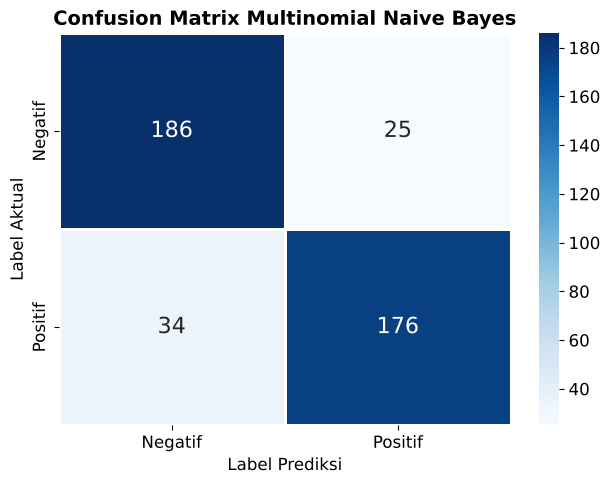

In [16]:
idx = np.arange(len(data))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
final_model = make_model("MNB, TF-IDF").fit(X_all[tr_idx], y_all[tr_idx])
y_pred = final_model.predict(X_all[te_idx])
proba = final_model.predict_proba(X_all[te_idx])[:, list(final_model.classes_).index("positive")]
y_true = y_all[te_idx]
print(f"Latih {len(tr_idx)} | uji {len(te_idx)}")
print(f"Akurasi hold-out: {fmt_pct(accuracy_score(y_true, y_pred) * 100, 2)}")
rep = classification_report(y_true, y_pred, labels=LABELS, digits=3, output_dict=True)
print(classification_report(y_true, y_pred, labels=LABELS, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=LABELS)
tab5 = pd.DataFrame(cm, index=["Aktual Negatif", "Aktual Positif"], columns=["Prediksi Negatif", "Prediksi Positif"])
tab5["Total"] = tab5.sum(axis=1); tab5.loc["Total"] = tab5.sum()
save_table(tab5, "tabel5_confusion_matrix.csv", index=True); display(tab5)

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="white",
            xticklabels=["Negatif", "Positif"], yticklabels=["Negatif", "Positif"], annot_kws={"size": 16})
plt.title("Confusion Matrix Multinomial Naive Bayes", fontsize=14, fontweight="bold")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()
save("fig5_confusion_matrix.png")

## 12. Pembanding model & ablasi preprocessing (Tabel 6, Gambar 6)

,Model atau setelan,Accuracy (%),Macro F1 (%)
0,"MNB, TF-IDF (model utama)",88.20 ± 1.55,88.19 ± 1.55
1,"MNB, raw counts",87.30 ± 2.01,87.29 ± 2.02
2,"Linear SVM, TF-IDF",89.53 ± 2.13,89.53 ± 2.13
3,"Logistic regression, TF-IDF",89.63 ± 2.13,89.63 ± 2.13
4,"MNB, kata negasi dibuang",88.20 ± 1.70,88.19 ± 1.70
5,"MNB, tanpa normalisasi slang",86.96 ± 1.60,86.95 ± 1.60


MNB, raw counts: unggul di 0 fold, seri 1, kalah 4 (selisih rata-rata -0.90 poin vs MNB utama)
Linear SVM, TF-IDF: unggul di 4 fold, seri 0, kalah 1 (selisih rata-rata +1.33 poin vs MNB utama)
Logistic regression, TF-IDF: unggul di 4 fold, seri 1, kalah 0 (selisih rata-rata +1.43 poin vs MNB utama)
MNB, kata negasi dibuang: unggul di 1 fold, seri 3, kalah 1 (selisih rata-rata -0.00 poin vs MNB utama)
MNB, tanpa normalisasi slang: unggul di 0 fold, seri 0, kalah 5 (selisih rata-rata -1.24 poin vs MNB utama)


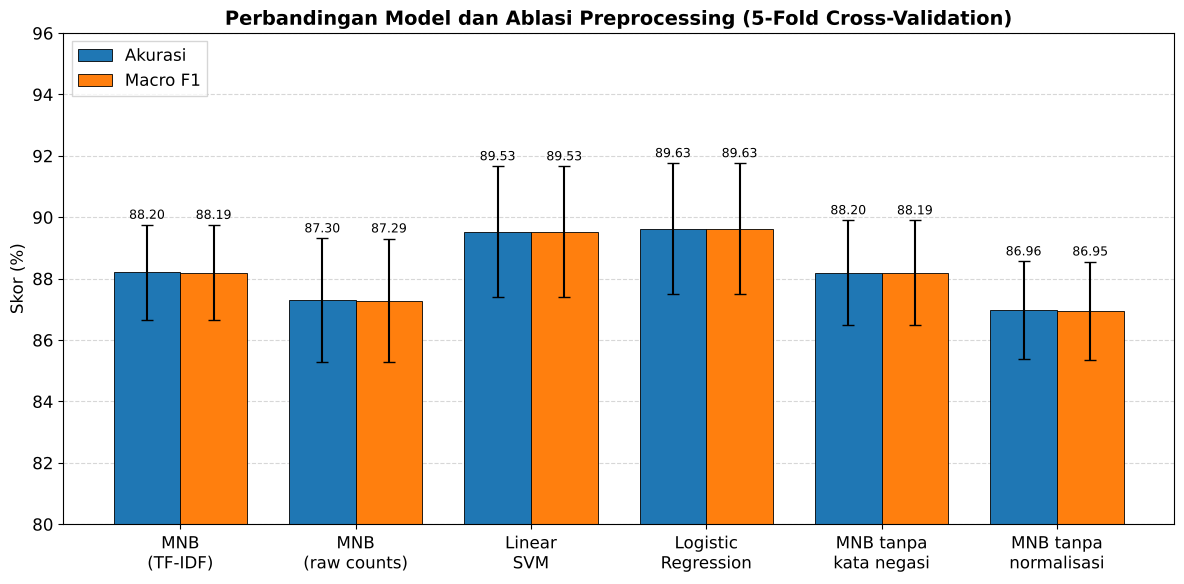

In [17]:
settings = [("MNB, TF-IDF (model utama)", "MNB, TF-IDF", X_all),
            ("MNB, raw counts", "MNB, raw counts", X_all),
            ("Linear SVM, TF-IDF", "Linear SVM, TF-IDF", X_all),
            ("Logistic regression, TF-IDF", "Logistic regression, TF-IDF", X_all),
            ("MNB, kata negasi dibuang", "MNB, TF-IDF", data["text_noneg"].values),
            ("MNB, tanpa normalisasi slang", "MNB, TF-IDF", data["text_nonorm"].values)]
rows, per_fold, per_fold_f1 = [], {}, {}
for label, name, X in settings:
    r = cv_mnb if label.startswith("MNB, TF-IDF") else run_cv(name, X)
    per_fold[label], per_fold_f1[label] = r["Accuracy"].values, r["F1"].values
    rows.append({"Model atau setelan": label,
                 "Accuracy (%)": f"{r['Accuracy'].mean():.2f} ± {r['Accuracy'].std(ddof=1):.2f}",
                 "Macro F1 (%)": f"{r['F1'].mean():.2f} ± {r['F1'].std(ddof=1):.2f}"})
tab6 = pd.DataFrame(rows)
save_table(tab6, "tabel6_pembanding_ablasi.csv"); display(tab6)

base = per_fold["MNB, TF-IDF (model utama)"]
win_loss = {}
for label in list(per_fold)[1:]:
    d = per_fold[label] - base
    win_loss[label] = {"menang": int(np.sum(d > 1e-9)), "seri": int(np.sum(np.abs(d) <= 1e-9)),
                       "kalah": int(np.sum(d < -1e-9)), "selisih": float(d.mean())}
    print(f"{label}: unggul di {win_loss[label]['menang']} fold, seri {win_loss[label]['seri']}, "
          f"kalah {win_loss[label]['kalah']} (selisih rata-rata {d.mean():+.2f} poin vs MNB utama)")
pd.DataFrame(per_fold, index=[f"Fold {i}" for i in range(1, 6)]).round(2).to_csv(
    os.path.join(OUT_DIR, "akurasi_per_fold_semua_model.csv"))

# Gambar 6: perbandingan model dan ablasi
nama_model = ["MNB\n(TF-IDF)", "MNB\n(raw counts)", "Linear\nSVM", "Logistic\nRegression",
              "MNB tanpa\nkata negasi", "MNB tanpa\nnormalisasi"]
akurasi = [per_fold[k].mean() for k in per_fold]
akurasi_sd = [per_fold[k].std(ddof=1) for k in per_fold]
f1 = [per_fold_f1[k].mean() for k in per_fold_f1]
f1_sd = [per_fold_f1[k].std(ddof=1) for k in per_fold_f1]
x = np.arange(len(nama_model))
lebar = 0.38
plt.figure(figsize=(12, 6))
plt.bar(x - lebar / 2, akurasi, lebar, yerr=akurasi_sd, capsize=4, label="Akurasi",
        color="tab:blue", edgecolor="black", linewidth=0.6)
plt.bar(x + lebar / 2, f1, lebar, yerr=f1_sd, capsize=4, label="Macro F1",
        color="tab:orange", edgecolor="black", linewidth=0.6)
for i in range(len(x)):
    plt.text(x[i] - lebar / 2, akurasi[i] + akurasi_sd[i] + 0.2, f"{akurasi[i]:.2f}", ha="center", fontsize=9)
    plt.text(x[i] + lebar / 2, f1[i] + f1_sd[i] + 0.2, f"{f1[i]:.2f}", ha="center", fontsize=9)
plt.xticks(x, nama_model)
plt.ylim(80, 96)
plt.ylabel("Skor (%)")
plt.title("Perbandingan Model dan Ablasi Preprocessing (5-Fold Cross-Validation)", fontsize=14, fontweight="bold")
plt.legend(loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.tight_layout()
save("fig6_perbandingan_model.png")

## 13. Analisis error hold-out
File `hasil/error_holdout.csv` berisi semua komentar uji yang salah klasifikasi. Isi kolom `kode_error` dengan salah satu: **label** (label leksikon keliru/sarkasme), **negasi** (negasi atau perbandingan), **slang** (slang/typo/kata ambigu), **konteks** (kata netral yang sering muncul di kelas lain mengalahkan kata sentimen), **campuran** (campuran/netral/permintaan).

In [18]:
ERR_PATH = os.path.join(OUT_DIR, "error_holdout.csv")
err = data.iloc[te_idx].assign(pred=y_pred, p_positive=proba.round(3))
err = err[err["label"] != err["pred"]][["comment_no", "text_original", "text_final", "lex_hits", "label", "pred", "p_positive"]]
if not os.path.exists(ERR_PATH):
    err.assign(kode_error="", catatan="").to_csv(ERR_PATH, index=False)
    print(f"{len(err)} komentar salah klasifikasi diekspor ke {rel(ERR_PATH)}")
else:
    print("File error sudah ada, tidak ditimpa:", rel(ERR_PATH))
print(f"FP (negatif diprediksi positif): {(err.label == 'negative').sum()} | FN (positif diprediksi negatif): {(err.label == 'positive').sum()}")
err.head(10)

File error sudah ada, tidak ditimpa: hasil/error_holdout.csv
FP (negatif diprediksi positif): 25 | FN (positif diprediksi negatif): 34


,comment_no,text_original,text_final,lex_hits,label,pred,p_positive
158,3823,kaget dan ga jdi nntn. nggu bsk aja pas anak2 sekolah biar fokus dan tdk terganggu.,kaget tidak jadi tonton nggu besok pas anak sekolah biar fokus tidak ganggu,terganggu(+3),positive,negative,0.402
1729,14642,yaudah jangan nangis 😭,yaudah jangan tangis,menangis(+5),positive,negative,0.287
782,18813,"aku kak,sambil istirahat jam makan😭",istirahat jam makan,istirahat(-2),negative,positive,0.524
1605,469,"Tau ga kak nad... aku ga berani nonton khw eps 400 ini sampe2 aku ajak ibuk aku buat nnton khw ini huhu, agak seram ...",tau tidak tidak berani tonton episode ajak ibuk buat tonton huhu seram biasa berani tonton sendiri ibuk kantuk kantu...,seram(-4) sehat(+3),negative,positive,0.691
1054,17412,​ @erikanto-i4k4g horor gak si takut bgttt,horor tidak takut,takut(+4),positive,negative,0.227
1111,895,"Baru selesai kami wakk.... udah makan, udah minum, udah cuci piring, udah lipat baju, baru selesai ceritanya wawak.....",baru selesai wakk makan minum cuci piring lipat baju baru selesai cerita luar biasa ajar apa alas jangan pernah seku...,iblis(-4),negative,positive,0.585
402,5307,Sayang nya wanita tidak bisa berkembang biak dengan cara membelah diri 😔,sayang wanita tidak bisa kembang biak cara belah diri,sayang(+3) berkembang(-3) cara(-3) membelah(-5),negative,positive,0.520
830,6209,Gua nyelesain yang kemarin,gua selesai kemarin,menyelesaikan(+3),positive,negative,0.424
827,9207,"Mgkin aja dia itu sayang istri juga tp krn cm 2 pilihan dia pasti nimbang lg, kl anak nya masi kecil dia ad rasa kas...",mungkin sayang istri pilih nimbang kalo anak kecil rasa kasihan kalo tidak pilih modar,sayang(+3) pilihan(+5) kasihan(-3),positive,negative,0.329
83,9313,Sayangnya tidak ada kehidupan selanjutnya,sayang tidak hidup lanjut,sayangnya(-3),negative,positive,0.709


In [19]:
e = pd.read_csv(ERR_PATH, keep_default_na=False)
if (e["kode_error"].str.strip() != "").any():
    rek = e["kode_error"].str.strip().str.lower().value_counts().rename_axis("Kode").to_frame("Jumlah")
    rek["Persen (%)"] = (rek["Jumlah"] / len(e) * 100).round(1)
    save_table(rek, "rekap_error_holdout.csv", index=True); display(rek)
else:
    print("Kolom kode_error belum diisi.")

,Jumlah,Persen (%)
Kode,,
label,31,52.5
campuran,11,18.6
negasi,10,16.9
slang,4,6.8
konteks,3,5.1


## 14. Analisis aspek (Tabel 7, Gambar 7)
Aturan kata kunci (regex, mencocokkan kata utuh beserta imbuhan akhirnya) dijalankan pada teks hasil normalisasi **sebelum** stopword removal, untuk semua komentar berlabel positif dan negatif (sebelum undersampling). Satu komentar bisa punya beberapa aspek.

Basis: 1.482 komentar negatif dan 1.169 positif
  Negatif: 78,1% cocok dengan minimal satu aspek
  Positif: 58,3% cocok dengan minimal satu aspek


,Aspek,Contoh kata kunci,Neg. (%),Pos. (%),Rasio Pos/Neg
0,Suasana horor,"seram, horor, merinding, takut",49.8,5.0,0.10
1,Emosi sedih dan haru,"sedih, menangis, tangis, haru",24.2,5.0,0.21
2,Durasi video,"durasi, jam, panjang, menit",11.0,20.0,1.82
3,Cerita dan alur,"cerita, kisah, alur, plot",7.2,8.7,1.21
4,Doa untuk korban/narasumber,"fatihah, alfatihah, almarhum, alm",2.9,7.7,2.66
5,Apresiasi tim,"terima kasih, salut, keren, mantap",2.7,33.8,12.52
6,Kehadiran dan waktu nonton,"absen, hadir, cung, angkat tangan",2.4,1.7,0.71
7,Usulan film/adaptasi,"film, bioskop, layar lebar, sinetron",1.2,2.9,2.42
8,Narator dan penyampaian,"narasi, narator, membawakan, dibawakan",0.3,0.5,1.67
9,Iklan dan teknis,"iklan, sponsor, audio, musik",0.3,0.0,0.00


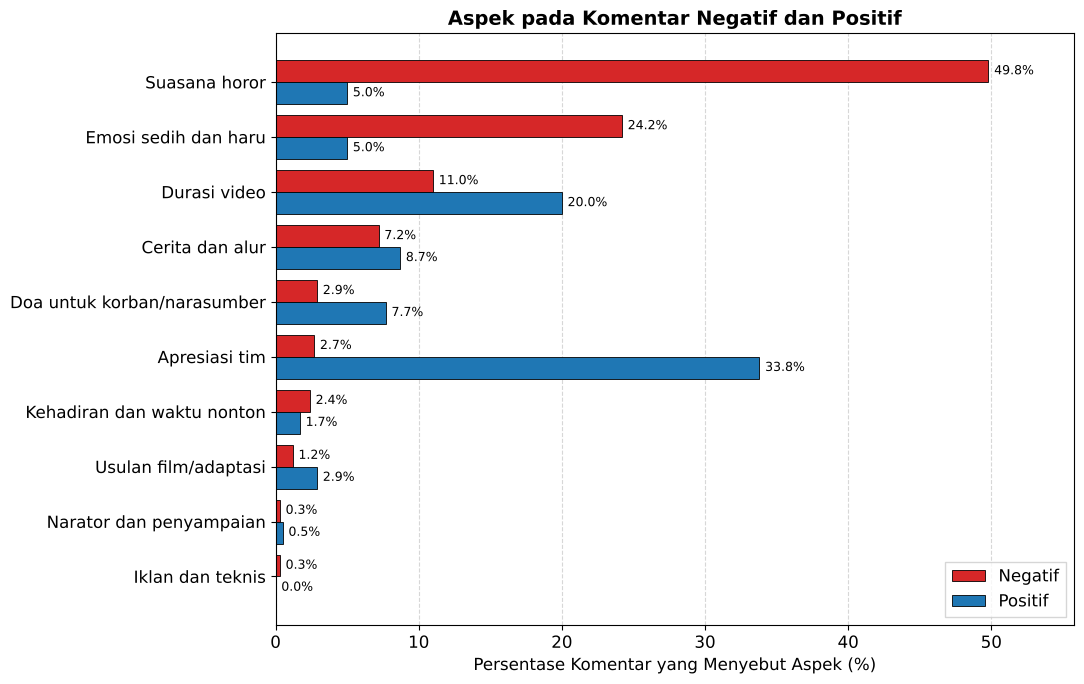

In [20]:
ASPECTS = {
    "Cerita dan alur":             ["cerita", "kisah", "alur", "plot", "ending", "tokoh", "twist", "kasus"],
    "Durasi video":                ["durasi", "jam", "panjang", "menit", "lama", "jumbo"],
    "Narator dan penyampaian":     ["narasi", "narator", "membawakan", "dibawakan", "bawain", "suara", "intonasi", "penyampaian", "cara cerita"],
    "Suasana horor":               ["seram", "horor", "merinding", "takut", "ngeri", "mistis", "hantu", "setan", "gaib"],
    "Emosi sedih dan haru":        ["sedih", "menangis", "tangis", "haru", "terharu", "nyesek", "air mata", "baper"],
    "Apresiasi tim":               ["terima kasih", "salut", "keren", "mantap", "terbaik", "gong", "bagus", "tim", "team"],
    "Doa untuk korban/narasumber": ["fatihah", "alfatihah", "almarhum", "alm", "tenang", "amin", "semoga", "narasumber"],
    "Usulan film/adaptasi":        ["film", "bioskop", "layar lebar", "sinetron", "series", "difilmkan"],
    "Kehadiran dan waktu nonton":  ["absen", "hadir", "cung", "angkat tangan", "nonton tanggal", "menonton tanggal"],
    "Iklan dan teknis":            ["iklan", "sponsor", "audio", "musik", "backsound", "editing", "kualitas", "buffering"],
}
ASPECT_RE = {a: re.compile(r"\b(?:" + "|".join(re.escape(k) for k in kws) + r")\w*", re.I) for a, kws in ASPECTS.items()}
labd = df[df["label"] != "neutral"].copy()
for a, rx in ASPECT_RE.items():
    labd[a] = labd["text_norm"].str.contains(rx)
labd["any_aspect"] = labd[list(ASPECTS)].any(axis=1)

tab7 = pd.DataFrame({
    "Aspek": list(ASPECTS),
    "Contoh kata kunci": [", ".join(k[:4]) for k in ASPECTS.values()],
    "Neg. (%)": [labd.loc[labd.label == "negative", a].mean() * 100 for a in ASPECTS],
    "Pos. (%)": [labd.loc[labd.label == "positive", a].mean() * 100 for a in ASPECTS],
}).round(1).sort_values("Neg. (%)", ascending=False).reset_index(drop=True)
tab7["Rasio Pos/Neg"] = (tab7["Pos. (%)"] / tab7["Neg. (%)"].replace(0, np.nan)).round(2)
any_aspect = {c: labd.loc[labd.label == c, "any_aspect"].mean() * 100 for c in LABELS}
print(f"Basis: {fmt_int((labd.label == 'negative').sum())} komentar negatif dan {fmt_int((labd.label == 'positive').sum())} positif")
for c in LABELS:
    print(f"  {NAMA[c]}: {fmt_pct(any_aspect[c])} cocok dengan minimal satu aspek")
save_table(tab7, "tabel7_aspek.csv"); display(tab7)

# Gambar 7: persentase aspek pada komentar negatif dan positif
aspek = tab7["Aspek"].tolist()
neg_pct, pos_pct = tab7["Neg. (%)"].tolist(), tab7["Pos. (%)"].tolist()
y = np.arange(len(aspek))
tinggi = 0.4
plt.figure(figsize=(11, 7))
plt.barh(y - tinggi / 2, neg_pct, tinggi, label="Negatif", color="tab:red", edgecolor="black", linewidth=0.6)
plt.barh(y + tinggi / 2, pos_pct, tinggi, label="Positif", color="tab:blue", edgecolor="black", linewidth=0.6)
for i in range(len(aspek)):
    plt.text(neg_pct[i] + 0.4, y[i] - tinggi / 2, f"{neg_pct[i]:.1f}%", va="center", fontsize=9)
    plt.text(pos_pct[i] + 0.4, y[i] + tinggi / 2, f"{pos_pct[i]:.1f}%", va="center", fontsize=9)
plt.yticks(y, aspek)
plt.gca().invert_yaxis()
plt.xlim(0, max(neg_pct + pos_pct) * 1.12)
plt.xlabel("Persentase Komentar yang Menyebut Aspek (%)")
plt.title("Aspek pada Komentar Negatif dan Positif", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.tight_layout()
save("fig7_aspek.png")

## 15. Komentar per hari (Gambar 8)
Tanggal diperkirakan dari waktu relatif YouTube ("6 days ago"), jadi presisinya harian dan bisa bergeser satu hari.

label,positive,negative,neutral,total,% negatif dari berlabel
est_date,,,,,
2026-10-26,593,345,1942,2880,36.8
2026-10-27,186,286,3406,3878,60.6
2026-10-28,106,259,3216,3581,71.0
2026-10-29,64,84,865,1013,56.8
2026-10-30,63,191,1332,1586,75.2
2026-10-31,47,95,1191,1333,66.9
2026-11-01,83,190,3882,4155,69.6
2026-11-02,27,32,637,696,54.2


            negatif  negatif menyebut 'Suasana horor'
est_date                                             
2026-10-26      345                               107
2026-10-27      286                               125
2026-10-28      259                               161
2026-10-29       84                                37
2026-10-30      191                               107
2026-10-31       95                                50
2026-11-01      190                               129
2026-11-02       32                                22


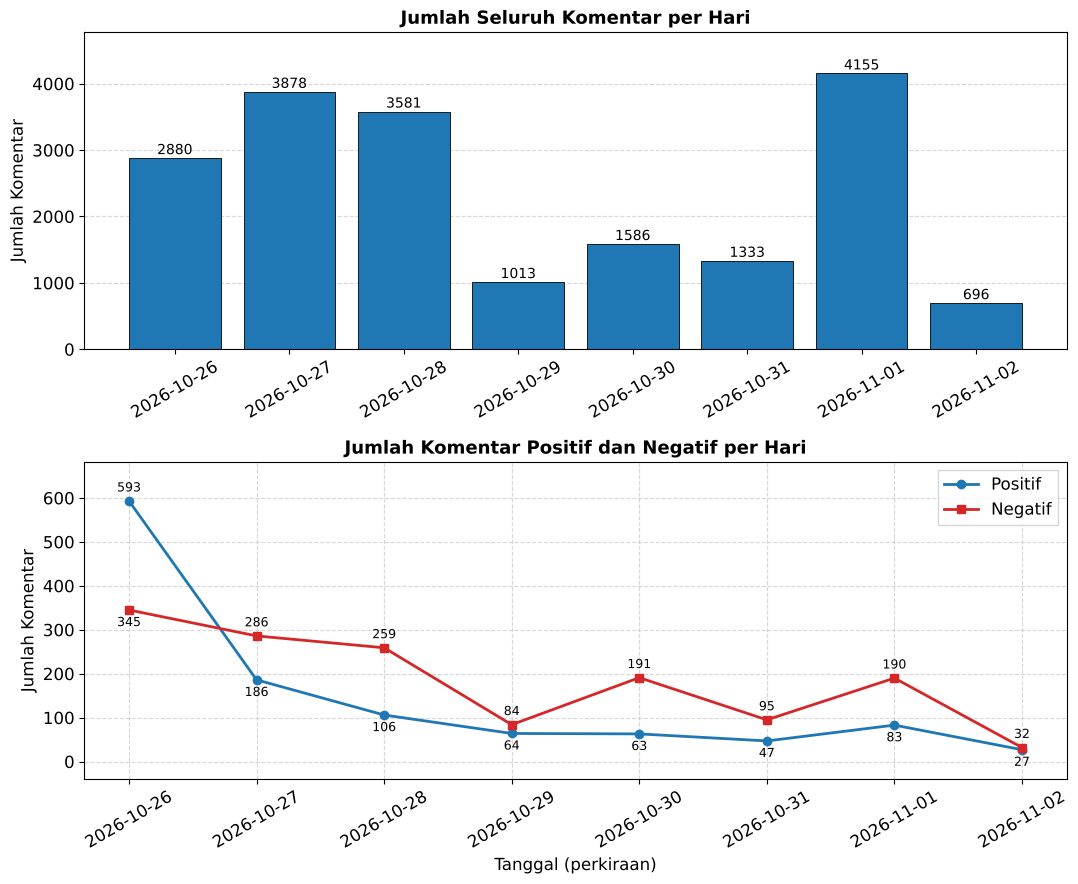

In [21]:
daily = (df.dropna(subset=["est_date"]).groupby(["est_date", "label"]).size()
           .unstack(fill_value=0).reindex(columns=["positive", "negative", "neutral"], fill_value=0))
daily["total"] = daily.sum(axis=1)
daily["% negatif dari berlabel"] = (daily["negative"] / (daily["positive"] + daily["negative"]) * 100).round(1)
save_table(daily, "jumlah_komentar_harian.csv", index=True); display(daily)

top_neg_aspect = tab7.iloc[0]["Aspek"]
neg_daily = labd[labd.label == "negative"].groupby("est_date")[top_neg_aspect].agg(["size", "sum"])
neg_daily.columns = ["negatif", f"negatif menyebut '{top_neg_aspect}'"]
save_table(neg_daily, "aspek_negatif_teratas_harian.csv", index=True); print(neg_daily)

tanggal = [str(d) for d in daily.index]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9))
ax1.bar(tanggal, daily["total"], color="tab:blue", edgecolor="black", linewidth=0.6)
for i, n in enumerate(daily["total"]):
    ax1.text(i, n + 60, str(n), ha="center", fontsize=10)
ax1.set_title("Jumlah Seluruh Komentar per Hari", fontsize=13, fontweight="bold")
ax1.set_ylabel("Jumlah Komentar")
ax1.set_ylim(0, daily["total"].max() * 1.15)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.set_axisbelow(True)
ax1.tick_params(axis="x", rotation=30)

ax2.plot(tanggal, daily["positive"], marker="o", color="tab:blue", linewidth=2, label="Positif")
ax2.plot(tanggal, daily["negative"], marker="s", color="tab:red", linewidth=2, label="Negatif")
for i, (p, n) in enumerate(zip(daily["positive"], daily["negative"])):
    atas, bawah = (p, n) if p >= n else (n, p)
    ax2.text(i, atas + 15, str(atas), ha="center", va="bottom", fontsize=9)
    ax2.text(i, bawah - 15, str(bawah), ha="center", va="top", fontsize=9)
ax2.set_title("Jumlah Komentar Positif dan Negatif per Hari", fontsize=13, fontweight="bold")
ax2.set_xlabel("Tanggal (perkiraan)")
ax2.set_ylabel("Jumlah Komentar")
ax2.set_ylim(-40, daily[["positive", "negative"]].max().max() * 1.15)
ax2.legend()
ax2.grid(linestyle="--", alpha=0.5)
ax2.tick_params(axis="x", rotation=30)
plt.tight_layout()
save("fig8_komentar_harian.png")

## 16. Prediksi komentar baru (Gambar 9)
Lima komentar buatan (bukan dari dataset) diproses dengan preprocessing yang sama lalu diklasifikasikan oleh model hold-out.

Teks      : Ceritanya seru banget, cara kak Nadia membawakan bikin betah sampai akhir. Terima kasih tim KHW!
Preproses : cerita seru cara bawa bikin betah akhir terima kasih tim
Prediksi  : Positif  (P(positif) = 0.908, P(negatif) = 0.092)

Teks      : Merinding banget dari awal, aku takut nonton sendirian malam-malam
Preproses : merinding awal takut tonton sendiri malam malam
Prediksi  : Negatif  (P(positif) = 0.051, P(negatif) = 0.949)

Teks      : Bosan, kepanjangan dan iklannya banyak banget, jelek episode kali ini
Preproses : bosan panjang iklan banyak jelek episode
Prediksi  : Positif  (P(positif) = 0.664, P(negatif) = 0.336)

Teks      : Durasinya lama tapi ceritanya bagus, nggak nyesel nonton
Preproses : durasi lama cerita bagus tidak sesal tonton
Prediksi  : Positif  (P(positif) = 0.740, P(negatif) = 0.260)

Teks      : Suaranya kurang jelas dan alurnya membingungkan, kecewa
Preproses : suara kurang jelas alur bingung kecewa
Prediksi  : Negatif  (P(positif) = 0.359, P(negatif)

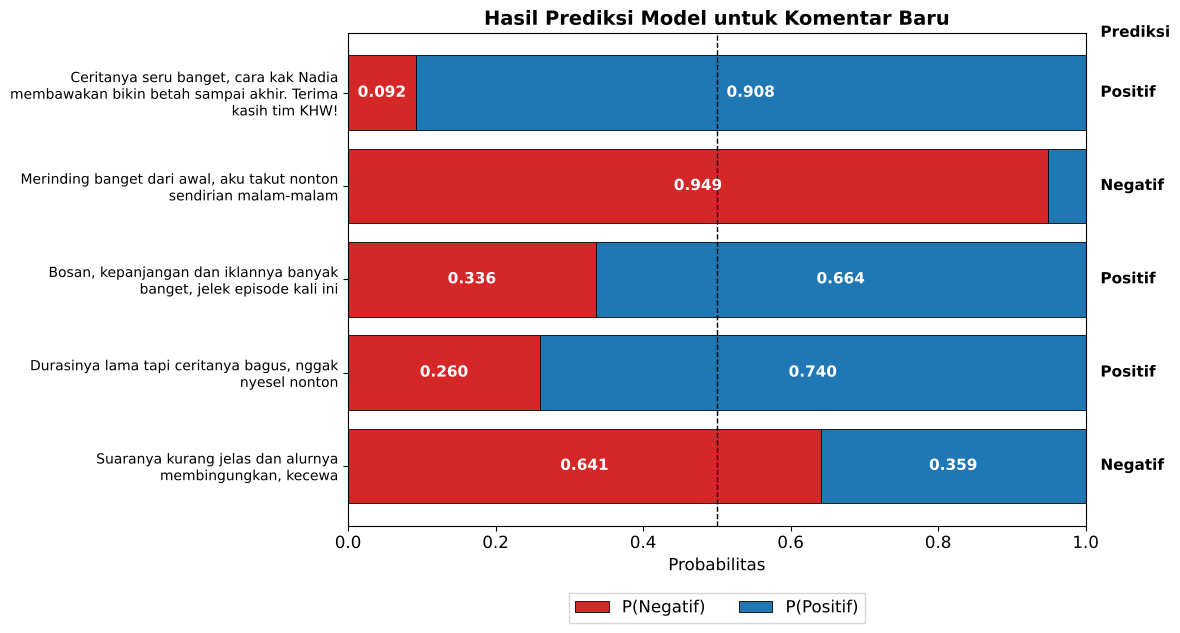

In [22]:
def predict_sentiment(text, model=final_model, verbose=True):
    final = " ".join(preprocess(text)[1])
    probs = dict(zip(model.classes_, model.predict_proba([final])[0]))
    label = max(probs, key=probs.get)
    if verbose:
        print(f"Teks      : {text}\nPreproses : {final}\nPrediksi  : {NAMA[label]}  "
              f"(P(positif) = {probs['positive']:.3f}, P(negatif) = {probs['negative']:.3f})\n")
    return label, probs

NEW_COMMENTS = [
    "Ceritanya seru banget, cara kak Nadia membawakan bikin betah sampai akhir. Terima kasih tim KHW!",
    "Merinding banget dari awal, aku takut nonton sendirian malam-malam",
    "Bosan, kepanjangan dan iklannya banyak banget, jelek episode kali ini",
    "Durasinya lama tapi ceritanya bagus, nggak nyesel nonton",
    "Suaranya kurang jelas dan alurnya membingungkan, kecewa",
]
preds = [predict_sentiment(t) for t in NEW_COMMENTS]
save_table(pd.DataFrame({"komentar": NEW_COMMENTS, "prediksi": [NAMA[p[0]] for p in preds],
                         "p_positif": [round(p[1]["positive"], 3) for p in preds],
                         "p_negatif": [round(p[1]["negative"], 3) for p in preds]}), "prediksi_komentar_baru.csv")

p_neg = [p[1]["negative"] for p in preds]
p_pos = [p[1]["positive"] for p in preds]
label_y = [textwrap.fill(t, 45) for t in NEW_COMMENTS]
y = np.arange(len(NEW_COMMENTS))
plt.figure(figsize=(12, 6.5))
plt.barh(y, p_neg, color="tab:red", edgecolor="black", linewidth=0.6, label="P(Negatif)")
plt.barh(y, p_pos, left=p_neg, color="tab:blue", edgecolor="black", linewidth=0.6, label="P(Positif)")
for i in range(len(y)):
    if p_neg[i] > 0.08:
        plt.text(p_neg[i] / 2, i, f"{p_neg[i]:.3f}", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    if p_pos[i] > 0.08:
        plt.text(p_neg[i] + p_pos[i] / 2, i, f"{p_pos[i]:.3f}", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    plt.text(1.02, i, NAMA[preds[i][0]], va="center", fontsize=11, fontweight="bold")
plt.text(1.02, -0.6, "Prediksi", fontsize=11, fontweight="bold")
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.yticks(y, label_y, fontsize=10)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.xlabel("Probabilitas")
plt.title("Hasil Prediksi Model untuk Komentar Baru", fontsize=14, fontweight="bold")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
save("fig9_prediksi_baru.png")

## 17. Ringkasan angka

In [23]:
summary = {
    "n_crawl": N_CRAWL, "n_after_initial_clean": int(len(df)), "n_reply": int(df["is_reply"].sum()),
    "rentang_tanggal": [str(df["est_date"].min()), str(df["est_date"].max())],
    "label_leksikon": {k: int((df.label == k).sum()) for k in order},
    "n_labelled": n_labelled, "n_empty_after_preprocess": int(n_empty), "n_dedup_merged": int(n_merged), "n_tie": n_tie,
    "setelah_dedup": {k: int(v) for k, v in counts.items()},
    "dataset_seimbang": int(len(data)), "per_kelas": n_min,
    "token_total": int(sum(all_tok.values())), "kata_unik": int(len(all_tok)), "token_per_kelas": n_tok,
    "contoh_kata_map": {k: (round(v, 6) if isinstance(v, float) else v) for k, v in word_calc.items()},
    "contoh_komentar_map": EXAMPLE_COMMENT, "contoh_komentar_map_token": ex_final, "contoh_komentar_map_pred": map_pred,
    "cv_mnb": {c: [round(cv_mnb[c].mean(), 2), round(cv_mnb[c].std(ddof=1), 2)] for c in ["Accuracy", "Precision", "Recall", "F1"]},
    "holdout": {"n_train": int(len(tr_idx)), "n_test": int(len(te_idx)),
                "accuracy": round(accuracy_score(y_true, y_pred) * 100, 2),
                "macro_f1": round(rep["macro avg"]["f1-score"], 3),
                "recall_neg": round(rep["negative"]["recall"], 3), "recall_pos": round(rep["positive"]["recall"], 3),
                "precision_neg": round(rep["negative"]["precision"], 3), "precision_pos": round(rep["positive"]["precision"], 3),
                "errors": int((y_true != y_pred).sum()), "cm_[TN,FP,FN,TP]": cm.ravel().tolist()},
    "pembanding": {k: [round(v.mean(), 2), round(v.std(ddof=1), 2)] for k, v in per_fold.items()},
    "pembanding_f1": {k: [round(v.mean(), 2), round(v.std(ddof=1), 2)] for k, v in per_fold_f1.items()},
    "menang_kalah_vs_mnb": win_loss,
    "aspek_any": {k: round(v, 1) for k, v in any_aspect.items()},
    "neutralize_story_emotion": NEUTRALIZE_STORY_EMOTION,
}
with open(os.path.join(OUT_DIR, "ringkasan_hasil.json"), "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps(summary, indent=2, ensure_ascii=False, default=str))

{
  "n_crawl": 20000,
  "n_after_initial_clean": 19122,
  "n_reply": 243,
  "rentang_tanggal": [
    "2026-10-26",
    "2026-11-02"
  ],
  "label_leksikon": {
    "positive": 1169,
    "negative": 1482,
    "neutral": 16471
  },
  "n_labelled": 2651,
  "n_empty_after_preprocess": 0,
  "n_dedup_merged": 253,
  "n_tie": 0,
  "setelah_dedup": {
    "negative": 1347,
    "positive": 1051
  },
  "dataset_seimbang": 2102,
  "per_kelas": 1051,
  "token_total": 17804,
  "kata_unik": 2813,
  "token_per_kelas": {
    "negative": 8628,
    "positive": 9176
  },
  "contoh_kata_map": {
    "kata": "ngeri",
    "n_neg": 22,
    "n_pos": 0,
    "p_w_neg": 0.00201,
    "p_w_pos": 8.3e-05,
    "p_d": 0.001047,
    "post_neg": 0.960159,
    "post_pos": 0.039841
  },
  "contoh_komentar_map": "Sakit banget jadi tata, aku sampai nangis sesegukan 😭",
  "contoh_komentar_map_token": "sakit jadi tata tangis sesegukan",
  "contoh_komentar_map_pred": "negative",
  "cv_mnb": {
    "Accuracy": [
      88.2,
      